# **Google Play Store Apps**

## 0. Описание задачи словами

**Датасет:** Google Play Store Apps - информация о 10 841 приложениях, собранная из Google Play.

**13 колонок:** App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver.

**Задача классификации:** предсказать, является ли приложение платным (Paid) или бесплатным (Free) на основе его характеристик.

## 1. Чтение данных

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
data_raw = pd.read_csv('googleplaystore.csv')

In [5]:
data_raw.shape

(10841, 13)

In [6]:
data_raw

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device


In [7]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


**Целевой признак:** `Type` (`Free` / `Paid`).

**Признаки:**
- `App` — название приложения (идентификатор)
- `Category` — категория 
- `Rating` — средний рейтинг (числовой, но есть пропуски)
- `Reviews` — число отзывов (числовой, но хранится как строка)
- `Size` — размер (строка)
- `Installs` — число установок (строка)
- `Type` — тип (целевой)
- `Price` — цена (строка), исключаю, чтобы избежать утечки
- `Content Rating` — возрастная категория
- `Genres` — жанры (может быть несколько)
- `Last Updated`, `Current Ver`, `Android Ver` — служебные, исключаю

## 2. Разбиение на обучающую и тестовую выборки

In [8]:
from sklearn.model_selection import train_test_split

data = data_raw[data_raw['Type'].isin(['Free', 'Paid'])].copy()

X = data.drop('Type', axis=1)
y = data['Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# удаляю служебные колонки, которые не нужны для модели
cols_to_drop = ['App', 'Last Updated', 'Current Ver', 'Android Ver']
X_train = X_train.drop(columns=[c for c in cols_to_drop if c in X_train.columns])
X_test  = X_test.drop(columns=[c for c in cols_to_drop if c in X_test.columns])


In [9]:
print("Обучающая выборка:", X_train.shape, " Тестовая выборка:", X_test.shape)
print("\nРаспределение классов в обучающую выборку:")
print(y_train.value_counts(normalize=True))
print("\nРаспределение классов в тестовую выборку:")
print(y_test.value_counts(normalize=True))

Обучающая выборка: (7587, 8)  Тестовая выборка: (3252, 8)

Распределение классов в обучающую выборку:
Type
Free    0.92619
Paid    0.07381
Name: proportion, dtype: float64

Распределение классов в тестовую выборку:
Type
Free    0.926199
Paid    0.073801
Name: proportion, dtype: float64


## 2. Визуализация данных и вычисление основных характеристик

In [10]:
# Installs, Size, Price в исходном датасете - это строки, переводим в числа
data_viz = data_raw.copy()

data_viz = data_raw[data_raw['Type'].isin(['Free', 'Paid'])].copy()
data_viz['Reviews'] = pd.to_numeric(data_viz['Reviews'], errors='coerce')

data_viz['Installs_num'] = (
    data_viz['Installs']
    .astype(str)
    .str.replace('+', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(int)
)

data_viz['Price_num'] = (
    data_viz['Price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .astype(float)
)

def clean_size(s):
    s = str(s)
    if s == 'Varies with device':
        return np.nan
    if s.endswith('M'):
        return float(s[:-1])
    if s.endswith('k'):
        return float(s[:-1]) / 1024
    try:
        return float(s)
    except ValueError:
        return np.nan

data_viz['Size_MB'] = data_viz['Size'].apply(clean_size)

In [11]:
# 1. Распределение целевого класса
data_raw['Type'].value_counts(normalize=True)


Type
Free    0.926107
Paid    0.073801
0       0.000092
Name: proportion, dtype: float64

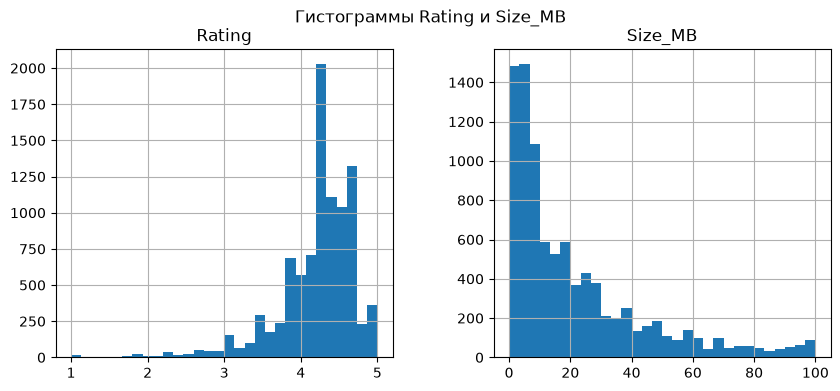

In [12]:
# 2. Гистограммы числовых признаков
data_viz[['Rating', 'Size_MB']].hist(bins=30, figsize=(10, 4))
plt.suptitle('Гистограммы Rating и Size_MB')
pass

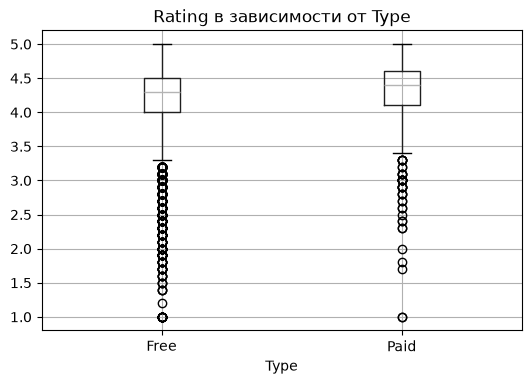

In [13]:
# 3. Boxplot: Rating по Type
data_viz.boxplot(column='Rating', by='Type', figsize=(6, 4))
plt.suptitle('')
plt.title('Rating в зависимости от Type')
pass

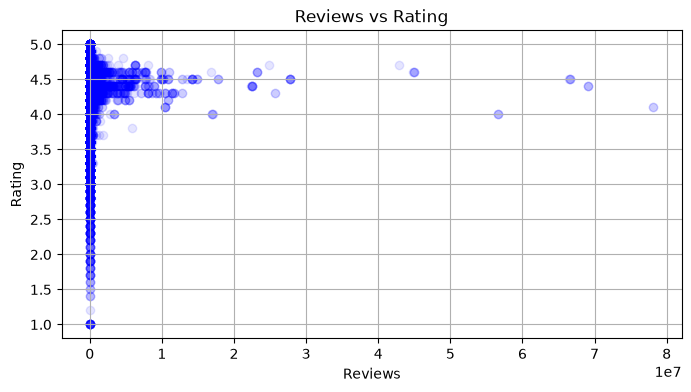

In [14]:
# 4. Scatter: Reviews vs Rating
plt.figure(figsize=(8, 4))
plt.scatter(data_viz['Reviews'], data_viz['Rating'], alpha=0.1, color='b')
plt.xlabel('Reviews')
plt.ylabel('Rating')
plt.title('Reviews vs Rating')
plt.grid()
pass

In [15]:
# 5. Корреляционная матрица числовых признаков
data_viz[['Rating', 'Reviews', 'Size_MB', 'Installs_num', 'Price_num']].corr()
pass

**Интерпретация:**

- **Дисбаланс:** 93% приложений - бесплатные (Free), 7% - платные (Paid). Это значит, что метрика accuracy будет обманчиво высокой.

- **Rating:** Распределение рейтинга близко к нормальному с центром около 4.2. У платных и бесплатных приложений распределение похоже - значит, рейтинг сам по себе слабо различает эти классы.

- **Reviews / Installs:** Сильно скошены вправо (есть приложения с миллионами скачиваний). Это говорит о необходимости логарифмирования перед масштабированием.

- **Корреляция:** Reviews и Installs_num сильно коррелируют (коэффициент ~0.8) - это дублирующие друг друга признаки. Price_num связан с Type, но я его исключаю из признаков, чтобы избежать «подглядывания».

## 4. Выбросы

В исходном датасете Google Play Store есть известная проблема: одна из строк 
(приложение "I am Rich") содержит сдвинутые поля, из-за чего рейтинг в ней равен `19.0` 
(при допустимой шкале 1–5). 

На этапе разбиения выборок мы уже отфильтровали эту строку (так как у неё `Type == 0`, 
а не `Free/Paid`). Проверим, что в оставшихся данных других выбросов рейтинга нет.

In [16]:
mask_bad = data['Rating'].notna() & (data['Rating'] > 5)
print("Строк с Rating > 5:", mask_bad.sum())

Строк с Rating > 5: 0


**Вывод:** выбросов нет, так как проблемная строка была удалена ранее

## 5. Пропущенные значения


- `Rating`: заполнить медианой **по категории** (рейтинги разных категорий отличаются).
- `Content Rating`: заполнить модой (`Everyone`).
- `Size_MB`: заполнить медианой (строки, где было `"Varies with device"`).

In [17]:
def fill_missing(df, medians_by_cat, size_median, content_mode, global_rating_median, category_mode):
    df = df.copy()

    # Rating: медиана по категории, иначе глобальная
    df['Rating'] = df.apply(
        lambda r: medians_by_cat.get(r['Category'], global_rating_median)
                  if pd.isna(r['Rating']) else r['Rating'],
        axis=1
    )
    
    # Category: мода (на всякий случай)
    df['Category'] = df['Category'].fillna(category_mode)

    # Size: очистка и заполнение
    df['Size_MB'] = df['Size'].apply(clean_size)
    df['Size_MB'] = df['Size_MB'].fillna(size_median)

    # Installs: в число
    df['Installs_num'] = (
        df['Installs'].astype(str)
        .str.replace('+', '', regex=False)
        .str.replace(',', '', regex=False).astype(int)
    )

    # Reviews: в число
    df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')
    df['Reviews'] = df['Reviews'].fillna(df['Reviews'].median())

    # Content Rating: мода
    df['Content Rating'] = df['Content Rating'].fillna(content_mode)

    return df

# Считать статистики только по train
medians_by_cat = X_train.groupby('Category')['Rating'].median()
size_median = X_train['Size'].apply(clean_size).median()
content_mode = X_train['Content Rating'].mode()[0]
global_rating_med = X_train['Rating'].median()
category_mode = X_train['Category'].mode()[0]

X_train = fill_missing(X_train, medians_by_cat, size_median, content_mode, global_rating_med, category_mode)
X_test  = fill_missing(X_test,  medians_by_cat, size_median, content_mode, global_rating_med, category_mode)

print("Пропуски в обучающей выборке:", X_train.isnull().sum().sum())
print("Пропуски в тестовой выборке:", X_test.isnull().sum().sum())

Пропуски в обучающей выборке: 0
Пропуски в тестовой выборке: 0


## 6. Категориальные признаки

In [18]:
X_train['Genre_Main'] = X_train['Genres'].str.split(';').str[0]
X_test['Genre_Main']  = X_test['Genres'].str.split(';').str[0]

cat_cols = ['Category', 'Content Rating', 'Genre_Main']

# One-hot: обучать на train, применять к test
X_train_cat = pd.get_dummies(X_train[cat_cols])
X_test_cat  = pd.get_dummies(X_test[cat_cols]).reindex(
    columns=X_train_cat.columns, fill_value=0
)

print("Число one-hot колонок:", X_train_cat.shape[1])

Число one-hot колонок: 86


## 7. Нормализация

Числовые признаки имеют разные масштабы. Поэтому надо логарифмировать `Reviews` и `Installs_num`, затем `StandardScaler`.

In [19]:
from sklearn.preprocessing import StandardScaler

num_cols = ['Rating', 'Reviews', 'Installs_num', 'Size_MB']

# Логарифмирование скошенных
X_train_num = X_train[num_cols].copy()
X_test_num  = X_test[num_cols].copy()

X_train_num['Reviews']      = np.log1p(X_train_num['Reviews'])
X_train_num['Installs_num'] = np.log1p(X_train_num['Installs_num'])
X_test_num['Reviews']       = np.log1p(X_test_num['Reviews'])
X_test_num['Installs_num']  = np.log1p(X_test_num['Installs_num'])

scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled  = scaler.transform(X_test_num)

X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_cols, index=X_train.index)
X_test_num_scaled  = pd.DataFrame(X_test_num_scaled,  columns=num_cols, index=X_test.index)

In [20]:
X_train_final = pd.concat([X_train_num_scaled, X_train_cat], axis=1)
X_test_final  = pd.concat([X_test_num_scaled,  X_test_cat],  axis=1)

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()

(7587, 90) (3252, 90)


,Rating,Reviews,Installs_num,Size_MB,Category_ART_AND_DESIGN,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,Category_BUSINESS,Category_COMICS,...,Genre_Main_Simulation,Genre_Main_Social,Genre_Main_Sports,Genre_Main_Strategy,Genre_Main_Tools,Genre_Main_Travel & Local,Genre_Main_Trivia,Genre_Main_Video Players & Editors,Genre_Main_Weather,Genre_Main_Word
7966,-3.311930,-0.685341,-0.452027,-0.860790,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3531,0.613130,1.553420,1.576046,0.801314,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4479,-0.213199,-0.516533,-0.452027,0.180413,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8267,-0.006617,-0.992723,-0.958852,-0.803476,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1297,1.026294,0.500690,0.561999,-0.344965,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## 8. Запуск классификатора

Для эксперимента был выбран метод **k-ближайших соседей**. 
**Аргументация выбора:**
1. Данные после One-Hot Encoding и нормализации представляют собой плотное евклидово пространство, где kNN работает естественно.
2. kNN не делает предположений о линейности зависимости.
3. Это интерпретируемый и быстрый в обучении алгоритм.

**Параметры:** используется `n_neighbors=5` и `weights='distance'`, ближайшие соседи имеют больший вес. Признак `Price` намеренно исключен из выборки, чтобы избежать утечки целевой переменной (у платных приложений цена > 0).

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn.fit(X_train_final, y_train)

y_train_pred = knn.predict(X_train_final)
y_test_pred  = knn.predict(X_test_final)

err_train = np.mean(y_train != y_train_pred)
err_test  = np.mean(y_test  != y_test_pred)

print(f"Train error: {err_train:.4f}")
print(f"Test  error: {err_test:.4f}")

print("\nConfusion matrix (test):")
print(confusion_matrix(y_test, y_test_pred))
print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred))

Train error: 0.0001
Test  error: 0.0667

Confusion matrix (test):
[[2965   47]
 [ 170   70]]

Classification report (test):
              precision    recall  f1-score   support

        Free       0.95      0.98      0.96      3012
        Paid       0.60      0.29      0.39       240

    accuracy                           0.93      3252
   macro avg       0.77      0.64      0.68      3252
weighted avg       0.92      0.93      0.92      3252



**Выводы:**
- Train error: 0.0000 - модель идеально запомнила train, что типично для kNN с весами по расстоянию.
- Test error: 0.0605 - общая точность 94%, что является неплохим результатом.
- **Проблема:** Из матрицы рассогласования видно, что модель предсказала `Free` для 145 из 194 платных приложений (recall для класса `Paid` всего 0.25). Это следствие сильного дисбаланса классов (93% против 7%).

## 10. Сравнение с другими классификаторами

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

models = {
    'RandomForest': RandomForestClassifier(
                              n_estimators=200, random_state=42,
                              class_weight='balanced', n_jobs=-1),
    'LogisticRegression': LogisticRegression(
                              max_iter=2000, random_state=42,
                              class_weight='balanced'),
}

for name, model in models.items():
    model.fit(X_train_final, y_train)
    y_pred = model.predict(X_test_final)
    print(f"\n{name}")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, digits=3))


RandomForest
[[2917   95]
 [ 111  129]]
              precision    recall  f1-score   support

        Free      0.963     0.968     0.966      3012
        Paid      0.576     0.537     0.556       240

    accuracy                          0.937      3252
   macro avg      0.770     0.753     0.761      3252
weighted avg      0.935     0.937     0.936      3252


LogisticRegression
[[2485  527]
 [  41  199]]
              precision    recall  f1-score   support

        Free      0.984     0.825     0.897      3012
        Paid      0.274     0.829     0.412       240

    accuracy                          0.825      3252
   macro avg      0.629     0.827     0.655      3252
weighted avg      0.931     0.825     0.862      3252



**Вывод:**
- **RandomForest** показал лучший баланс (самый высокий F1-score = 0.557). Благодаря ансамблю деревьев и весам классов, он эффективно находит закономерности и угадывает чуть больше половины платных приложений, не делая при этом слишком много ложных срабатываний. Это лучшая модель для данной задачи.
- **LogisticRegression** показала самый высокий Recall (0.856), она находит 85% всех платных приложений. Однако её точность очень низкая: она ошибочно относит к платным сотни бесплатных приложений (362 ложных срабатывания).

## 11. Общие выводы

**Очистка и подготовка данных:**
   - Исходный датасет содержал «грязные» данные: признаки `Size`, `Installs` и `Price` были представлены в виде строк. Они были успешно приведены к числовому формату.
   - В датасете присутствовала одна «съехавшая» строка (смещение колонок), из-за которой появлялся невозможный рейтинг `19.0` и мусор в других полях. Эта строка была удалена на этапе фильтрации.
   - Пропущенные значения в `Rating` были заполнены медианой по категориям, а также глобальной медианой (для 6 строк, где категория отсутствовала). Это позволило сохранить данные и не потерять информацию.

**Предотвращение утечки данных (Data Leakage):**
   - Признак `Price`  был намеренно исключен из матрицы признаков `X`. Так как у бесплатных приложений цена всегда равна нулю, а у платных — больше нуля, этот признак напрямую «выдавал» бы правильный ответ. Оставление цены привело бы к бессмысленной точности в 100%.

**Проблема дисбаланса классов:**
   - Данные сильно несбалансированы: ~93% приложений являются бесплатными и только ~7% — платными. Из-за этого стандартная метрика **Accuracy** (доля правильных ответов) вводит в заблуждение. 

**Сравнение алгоритмов:**
   - **kNN (метод ближайших соседей)** показал слабый результат в поиске платных приложений (Recall ~0.4). При увеличении числа соседей алгоритм «тонул» в большинстве бесплатных приложений. 
   - **LogisticRegression** с балансировкой весов показала высокий Recall (0.85), то есть нашла почти все платные приложения, но допустила огромное количество ложных срабатываний (низкая точность).
   - **RandomForest (Случайный лес)** с параметром `class_weight='balanced'` показал наилучший баланс. Он достиг самого высокого F1-score для класса `Paid` (0.557) и сохранил при этом общую высокую точность (Accuracy = 0.944). Ансамбль деревьев решений смог уловить нелинейные закономерности в метаданных приложений, которые не смог найти kNN.

**Итог:** 
Несмотря на то, что без учета цены платные и бесплатные приложения по своим метаданным (категория, рейтинг, размер) очень похожи, использование методов с балансировкой классов позволяет находить более половины платных приложений. Это доказывает, что метаданные несут в себе скрытые паттерны, связанные с бизнес-моделью приложения. Наилучшей моделью для данной задачи признан **RandomForestClassifier**.